# saved file

In [37]:
df.to_csv(
    "../data/traffic_intelligence_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [40]:
import os
cleaned_path = "../data/traffic_intelligence_cleaned.csv"
source_path = "../data/traffic_intelligence_dataset_1lakh.csv"
df = pd.read_csv(cleaned_path if os.path.exists(cleaned_path) else source_path)

In [41]:
df.head()

,record_id,timestamp,location_name,latitude,longitude,road_type,lane_count,day_of_week,hour,is_weekend,...,prev_hour_congestion,congestion_level,target_congestion_next_hour,date,year,month,day,hour_from_timestamp,day_name,time_period
0,1,2024-01-01 00:04:00,Wakad Bridge,18.598795,73.763022,Highway,6,0,0,0,...,Low,Low,Low,2024-01-01,2024,1,1,0,Monday,Night
1,2,2024-01-01 00:09:00,Magarpatta Rd,18.515726,73.927038,Local,2,0,0,0,...,Low,Low,Low,2024-01-01,2024,1,1,0,Monday,Night
2,3,2024-01-01 00:11:00,Kharadi IT Park Rd,18.544116,73.934890,Highway,6,0,0,0,...,Low,Low,Low,2024-01-01,2024,1,1,0,Monday,Night
3,4,2024-01-01 00:15:00,Kothrud Depot,18.507846,73.801938,Local,2,0,0,0,...,Low,Low,Low,2024-01-01,2024,1,1,0,Monday,Night
4,5,2024-01-01 00:16:00,Swargate Signal,18.499092,73.859743,Local,2,0,0,0,...,Low,Low,Low,2024-01-01,2024,1,1,0,Monday,Night


In [42]:
print(df.columns.tolist())

['record_id', 'timestamp', 'location_name', 'latitude', 'longitude', 'road_type', 'lane_count', 'day_of_week', 'hour', 'is_weekend', 'is_holiday', 'weather_condition', 'temperature_C', 'rainfall_mm', 'visibility_km', 'humidity_percent', 'wind_speed_kmph', 'vehicle_count', 'occupancy_percent', 'avg_speed_kmph', 'travel_time_index', 'signal_status', 'public_transport_delay_min', 'pollution_index_aqi', 'event_nearby', 'construction_work', 'accident_reported', 'accident_severity', 'prev_hour_congestion', 'congestion_level', 'target_congestion_next_hour', 'date', 'year', 'month', 'day', 'hour_from_timestamp', 'day_name', 'time_period']


# Correlation Matrix

In [43]:
numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

correlation

,record_id,latitude,longitude,lane_count,day_of_week,hour,is_weekend,is_holiday,temperature_C,rainfall_mm,...,travel_time_index,public_transport_delay_min,pollution_index_aqi,event_nearby,construction_work,accident_reported,year,month,day,hour_from_timestamp
record_id,1.000000,0.003966,-0.005521,-0.004095,0.013077,0.001031,0.012372,-0.001749,-0.086731,0.025861,...,0.005792,0.003371,-0.003973,0.007949,0.000788,-0.000115,NaN,0.996514,0.082340,0.001031
latitude,0.003966,1.000000,-0.428342,0.148366,-0.002956,-0.002226,-0.002392,-0.000284,-0.000420,0.004951,...,0.054528,0.049290,0.055630,-0.001374,0.001733,-0.000625,NaN,0.003749,0.002814,-0.002226
longitude,-0.005521,-0.428342,1.000000,-0.220397,0.004004,0.002968,0.003260,0.000695,-0.001601,-0.005559,...,-0.058570,-0.053426,-0.117909,0.001355,-0.000354,-0.007113,NaN,-0.005741,0.002009,0.002968
lane_count,-0.004095,0.148366,-0.220397,1.000000,-0.000531,-0.000276,-0.000652,0.002818,-0.004131,0.007561,...,0.275238,0.250889,0.544510,0.001213,-0.000828,0.040867,NaN,-0.004066,-0.000639,-0.000276
day_of_week,0.013077,-0.002956,0.004004,-0.000531,1.000000,0.006143,0.789697,-0.049414,0.016959,0.005465,...,-0.081381,-0.075293,-0.060091,-0.000925,0.002008,0.001141,NaN,0.011747,0.015820,0.006143
hour,0.001031,-0.002226,0.002968,-0.000276,0.006143,1.000000,0.003256,0.005616,0.002364,-0.003476,...,0.285240,0.256498,0.250296,-0.001757,0.002703,0.020359,NaN,-0.001600,-0.001436,1.000000
is_weekend,0.012372,-0.002392,0.003260,-0.000652,0.789697,0.003256,1.000000,-0.117192,0.005008,0.005900,...,-0.102832,-0.093982,-0.076711,-0.000752,0.000599,-0.001266,NaN,0.011090,0.015043,0.003256
is_holiday,-0.001749,-0.000284,0.000695,0.002818,-0.049414,0.005616,-0.117192,1.000000,0.055673,-0.006227,...,0.012895,0.012208,0.010200,-0.007114,-0.002819,0.005936,NaN,-0.002103,0.004051,0.005616
temperature_C,-0.086731,-0.000420,-0.001601,-0.004131,0.016959,0.002364,0.005008,0.055673,1.000000,0.002869,...,-0.000656,0.000849,-0.000032,-0.004257,-0.003730,-0.001216,NaN,-0.086591,0.009615,0.002364
rainfall_mm,0.025861,0.004951,-0.005559,0.007561,0.005465,-0.003476,0.005900,-0.006227,0.002869,1.000000,...,0.297914,0.266167,-0.015385,0.001651,0.000734,0.109311,NaN,0.025849,0.002463,-0.003476


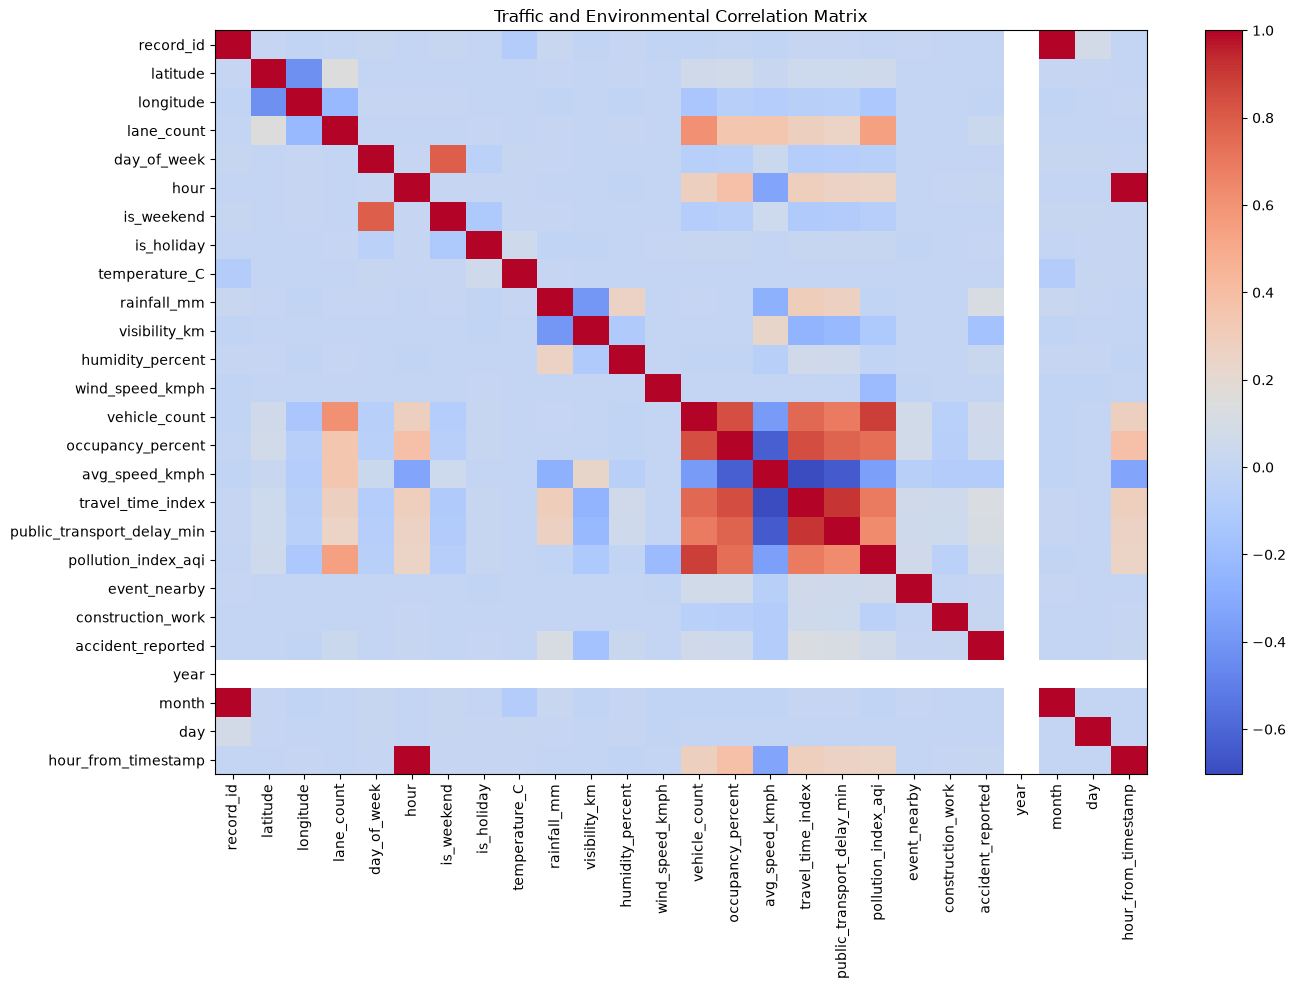

In [44]:
plt.figure(figsize=(14, 10))

plt.imshow(correlation, cmap="coolwarm", aspect="auto")
plt.colorbar()

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title("Traffic and Environmental Correlation Matrix")
plt.tight_layout()
plt.show()

# Rainfall vs Traffic

In [45]:
df["rainfall_mm"].describe()

count    100000.000000
mean          3.146869
std           8.199273
min           0.000000
25%           0.000000
50%           0.000000
75%           1.500000
max          90.200000
Name: rainfall_mm, dtype: float64

In [47]:
df["rainfall_category"] = pd.cut(
    df["rainfall_mm"],
    bins=[-1, 0, 2, 10, float("inf")],
    labels=["No Rain", "Light Rain", "Moderate Rain", "Heavy Rain"]
)

In [48]:
rainfall_analysis = df.groupby(
    "rainfall_category",
    observed=False
)["vehicle_count"].mean()

print(rainfall_analysis)

rainfall_category
No Rain          635.927023
Light Rain       644.409656
Moderate Rain    631.300416
Heavy Rain       638.298209
Name: vehicle_count, dtype: float64


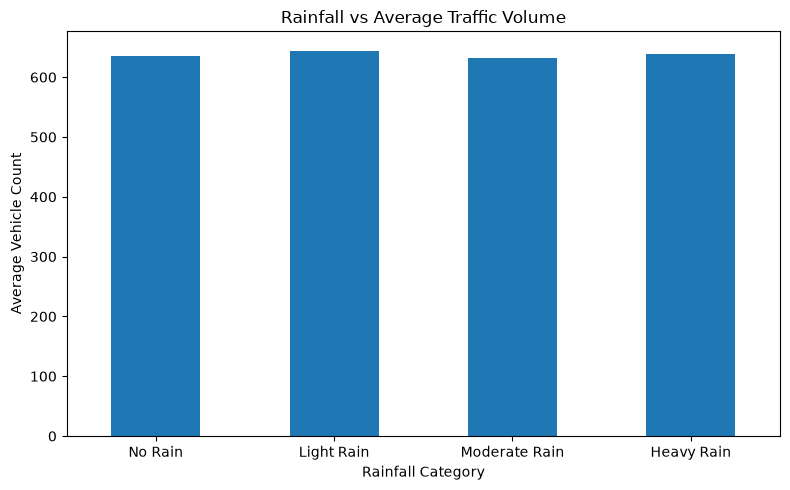

In [49]:
rainfall_analysis.plot(kind="bar", figsize=(8,5))

plt.title("Rainfall vs Average Traffic Volume")
plt.xlabel("Rainfall Category")
plt.ylabel("Average Vehicle Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Visibility vs Speed

In [50]:
df[["visibility_km", "avg_speed_kmph"]].describe()

,visibility_km,avg_speed_kmph
count,100000.000000,100000.000000
mean,6.640600,24.099464
std,2.381516,11.184223
min,0.200000,2.900000
25%,5.490000,15.400000
50%,7.000000,22.900000
75%,8.490000,31.600000
max,10.000000,65.300000


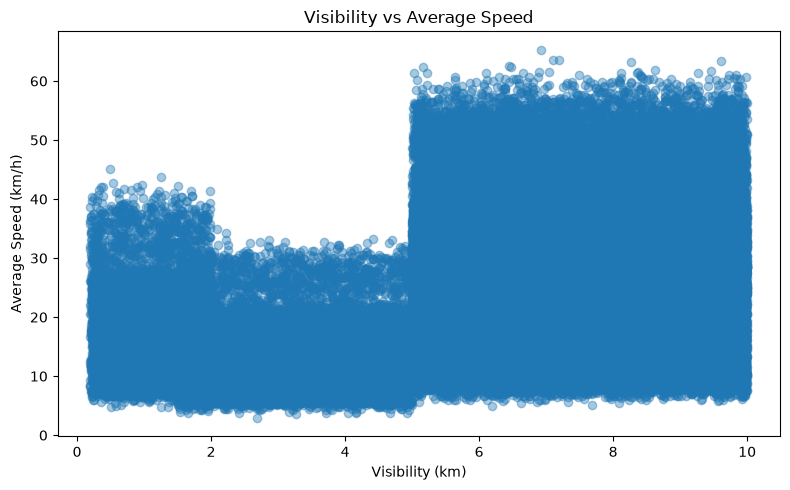

In [51]:
plt.figure(figsize=(8,5))

plt.scatter(
    df["visibility_km"],
    df["avg_speed_kmph"],
    alpha=0.4
)

plt.xlabel("Visibility (km)")
plt.ylabel("Average Speed (km/h)")
plt.title("Visibility vs Average Speed")

plt.tight_layout()
plt.show()

In [52]:
visibility_speed_corr = df[
    ["visibility_km", "avg_speed_kmph"]
].corr()

print(visibility_speed_corr)

                visibility_km  avg_speed_kmph
visibility_km        1.000000        0.234045
avg_speed_kmph       0.234045        1.000000


# STEP 4 — Weather Condition vs Congestion

In [53]:
weather_congestion = df.groupby(
    "weather_condition"
)["travel_time_index"].mean().sort_values(
    ascending=False
)

print(weather_congestion)

weather_condition
Heavy Rain    3.921664
Foggy         3.083982
Light Rain    2.691631
Clear         2.155931
Cloudy        2.146594
Windy         2.136616
Name: travel_time_index, dtype: float64


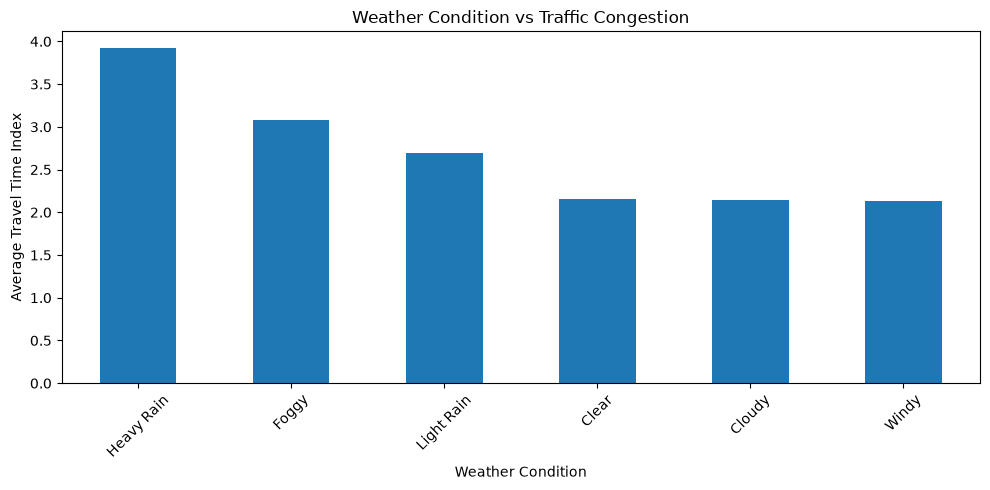

In [54]:
weather_congestion.plot(
    kind="bar",
    figsize=(10,5)
)

plt.title("Weather Condition vs Traffic Congestion")
plt.xlabel("Weather Condition")
plt.ylabel("Average Travel Time Index")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# STEP 5 — Accidents vs Congestion

### Compare accident and non-accident records

In [55]:
accident_congestion = df.groupby(
    "accident_reported"
)["travel_time_index"].mean()

print(accident_congestion)

accident_reported
0    2.458572
1    3.614604
Name: travel_time_index, dtype: float64


### compare speed:

In [56]:
df.groupby(
    "accident_reported"
)["avg_speed_kmph"].mean()

accident_reported
0    24.264002
1    18.199189
Name: avg_speed_kmph, dtype: float64

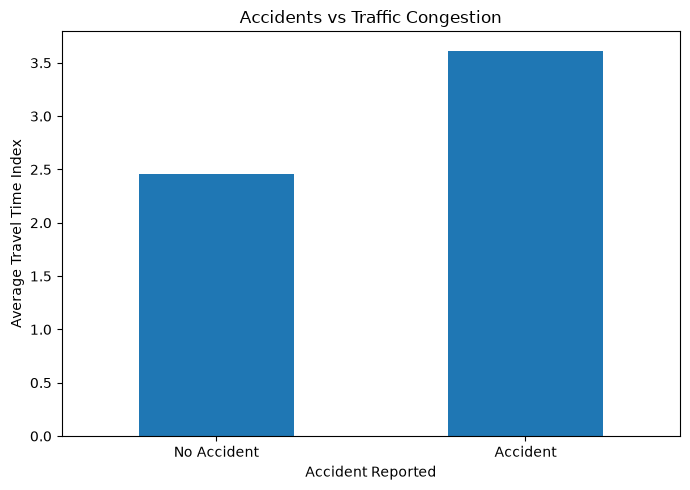

In [57]:
accident_congestion.plot(
    kind="bar",
    figsize=(7,5)
)

plt.title("Accidents vs Traffic Congestion")
plt.xlabel("Accident Reported")
plt.ylabel("Average Travel Time Index")
plt.xticks([0, 1], ["No Accident", "Accident"], rotation=0)

plt.tight_layout()
plt.show()

# STEP 6 — Events & Construction

In [58]:
df["event_nearby"].value_counts()

event_nearby
0    92085
1     7915
Name: count, dtype: int64

In [59]:
df["construction_work"].value_counts()

construction_work
0    90000
1    10000
Name: count, dtype: int64

In [60]:
event_congestion = df.groupby(
    "event_nearby"
)["travel_time_index"].mean()

print(event_congestion)

event_nearby
0    2.462745
1    2.806274
Name: travel_time_index, dtype: float64


In [61]:
construction_congestion = df.groupby(
    "construction_work"
)["travel_time_index"].mean()

print(construction_congestion)

construction_work
0    2.461059
1    2.749822
Name: travel_time_index, dtype: float64


# STEP 7 — Public Transport Delay

In [63]:
print(df.columns.tolist())

['record_id', 'timestamp', 'location_name', 'latitude', 'longitude', 'road_type', 'lane_count', 'day_of_week', 'hour', 'is_weekend', 'is_holiday', 'weather_condition', 'temperature_C', 'rainfall_mm', 'visibility_km', 'humidity_percent', 'wind_speed_kmph', 'vehicle_count', 'occupancy_percent', 'avg_speed_kmph', 'travel_time_index', 'signal_status', 'public_transport_delay_min', 'pollution_index_aqi', 'event_nearby', 'construction_work', 'accident_reported', 'accident_severity', 'prev_hour_congestion', 'congestion_level', 'target_congestion_next_hour', 'date', 'year', 'month', 'day', 'hour_from_timestamp', 'day_name', 'time_period', 'rainfall_category']


In [64]:
df["public_transport_delay_min"].describe()

count    100000.000000
mean          9.976069
std          10.601499
min           0.000000
25%           2.700000
50%           5.900000
75%          13.400000
max          96.700000
Name: public_transport_delay_min, dtype: float64

In [65]:
public_transport_corr = df[
    ["public_transport_delay_min", "travel_time_index"]
].corr()

print(public_transport_corr)

                            public_transport_delay_min  travel_time_index
public_transport_delay_min                    1.000000           0.909677
travel_time_index                             0.909677           1.000000


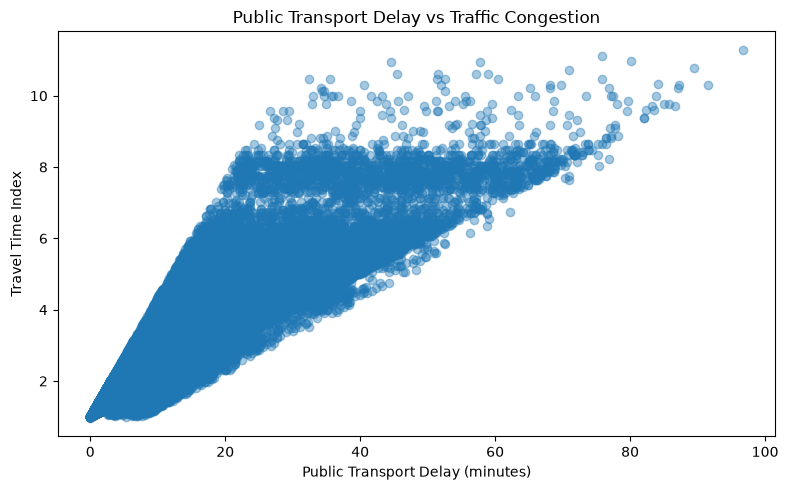

In [66]:
plt.figure(figsize=(8,5))

plt.scatter(
    df["public_transport_delay_min"],
    df["travel_time_index"],
    alpha=0.4
)

plt.xlabel("Public Transport Delay (minutes)")
plt.ylabel("Travel Time Index")
plt.title("Public Transport Delay vs Traffic Congestion")

plt.tight_layout()
plt.show()

# STEP 8 — Create an Environmental Analysis Summary

In [68]:
# STEP 8 — Overall Environmental Analysis Summary

print("=" * 70)
print("        OVERALL ENVIRONMENTAL ANALYSIS SUMMARY")
print("=" * 70)

print("\n1. Rainfall vs Traffic")
print(df.groupby(
    "rainfall_category",
    observed=False
)["vehicle_count"].mean())

print("\n2. Visibility vs Speed")
print(
    df[["visibility_km", "avg_speed_kmph"]]
    .corr()
)

print("\n3. Weather Condition vs Congestion")
print(
    df.groupby("weather_condition")["travel_time_index"]
    .mean()
    .sort_values(ascending=False)
)

print("\n4. Accident vs Congestion")
print(
    df.groupby("accident_reported")["travel_time_index"]
    .mean()
)

print("\n5. Nearby Events vs Congestion")
print(
    df.groupby("event_nearby")["travel_time_index"]
    .mean()
)

print("\n6. Construction Work vs Congestion")
print(
    df.groupby("construction_work")["travel_time_index"]
    .mean()
)

print("\n" + "=" * 70)
print("Overall environmental analysis completed successfully.")
print("=" * 70)

        OVERALL ENVIRONMENTAL ANALYSIS SUMMARY

1. Rainfall vs Traffic
rainfall_category
No Rain          635.927023
Light Rain       644.409656
Moderate Rain    631.300416
Heavy Rain       638.298209
Name: vehicle_count, dtype: float64

2. Visibility vs Speed
                visibility_km  avg_speed_kmph
visibility_km        1.000000        0.234045
avg_speed_kmph       0.234045        1.000000

3. Weather Condition vs Congestion
weather_condition
Heavy Rain    3.921664
Foggy         3.083982
Light Rain    2.691631
Clear         2.155931
Cloudy        2.146594
Windy         2.136616
Name: travel_time_index, dtype: float64

4. Accident vs Congestion
accident_reported
0    2.458572
1    3.614604
Name: travel_time_index, dtype: float64

5. Nearby Events vs Congestion
event_nearby
0    2.462745
1    2.806274
Name: travel_time_index, dtype: float64

6. Construction Work vs Congestion
construction_work
0    2.461059
1    2.749822
Name: travel_time_index, dtype: float64

Overall environmenta